<div style="display:flex; align-items:center; gap:18px; text-align:left">

<div>
<p>Ingeniería en Información y Control de Gestión</p>
<p>Facultad de Economía y Negocios</p>
<p>Introducción a Machine Learning</p>
<p>Semana 10: Interpretabilidad con SHAP</p>
</div>
</div>

# 10 · Interpretabilidad con SHAP

> **La pregunta de hoy:** Cobranza ya usa el random forest para decidir a quién llamar primero. Si
> pregunta por qué marcó a un cliente con 85 %, ¿qué le podemos responder y qué no podemos prometerle?

Tres tiempos: **yo lo hago** (abrir el modelo y leer qué usa en conjunto), **lo hacemos juntos**
(explicar dos clientes y leer la relación con la mora) y **lo hacen ustedes** (auditar los peores
errores y escribir qué falta en el archivo).

## Preparación del entorno

En Colab estas librerías ya vienen instaladas; la celda queda para correr fuera de Colab. La siguiente
define `num`, que escribe las cifras con punto de miles y coma decimal, y `pts`, que escribe una
diferencia de probabilidad en **puntos porcentuales** con su signo.

In [1]:
%%capture
!pip install -q pandas numpy scikit-learn matplotlib shap

In [2]:
from IPython.display import Markdown, display  # muestra frases con las cifras ya calculadas

def num(x, dec=0):
    # miles con punto, decimales con coma y el menos tipográfico
    texto = f'{x:,.{dec}f}'.replace(',', '@').replace('.', ',').replace('@', '.')
    return texto.replace('-', '−')

def pts(x):
    # 0,266 de probabilidad se escribe +26,6 puntos
    return ('+' if x >= 0 else '') + num(100 * x, 1)

## Cargar datos

La cartera de cobranza de **tarjetas de crédito**, `riesgo_impago.csv`, la misma de las sesiones 7 y 8.

<!-- contrato: accion=fijar-base -->

In [3]:
import os                # revisa si el archivo está en una carpeta local
import pandas as pd      # la librería de tablas

REPO = 'https://raw.githubusercontent.com/sebastiancontz/ust-introduccion-machine-learning-colab/main/ediciones/2026/datasets/'
BASE = '../datasets/' if os.path.exists('../datasets') else REPO

datos = pd.read_csv(BASE + 'riesgo_impago.csv')
print('registros y columnas:', datos.shape)

registros y columnas: (6000, 16)


## El encuadre: lo que se conserva y lo que empieza

- **Unidad de observación:** un registro es un **cliente observado en un mes**.
- **Objetivo:** si el cliente **incumple el pago del mes siguiente** (`incumplio_pago`). La clase
  positiva es **incumplir**: todo lo que explicamos hoy es la **probabilidad de impago**.
- **Se conserva:** el archivo, la partición con semilla 42 y el **bosque que ganó la sesión 8**. Hoy no
  se compite ni se ajusta nada.
- **Empieza:** abrir ese modelo y explicar qué usa, para poder defenderlo.

<!-- contrato: accion=declarar-positiva -->

In [4]:
y = datos['incumplio_pago'].map({'no': 0, 'si': 1})  # 1 = incumple, la clase positiva

COLUMNAS_CAT = ['nivel_educacion']
COLUMNAS_NUM = []
for columna in datos.columns:  # todas menos el identificador, el objetivo y la categórica
    if columna not in ['id_cliente', 'incumplio_pago'] + COLUMNAS_CAT:
        COLUMNAS_NUM.append(columna)
X = datos[COLUMNAS_NUM + COLUMNAS_CAT]

### La partición de siempre

Es la de las sesiones 7 y 8: 20 % a prueba, estratificada y con `random_state=42`. Hoy basta con el primer
corte: `X_trainval` (entrenamiento y validación juntos), con el que la sesión 8 reentrenó al ganador, y
`X_test`, los clientes que el modelo nunca vio.

**Por qué hoy se mira prueba más de una vez:** el modelo ya quedó elegido y congelado en la sesión 8.
Explicarlo sobre prueba es la **auditoría final** antes de entregarlo a Cobranza; nada de lo que se vea
se usa para cambiarlo. Si un hallazgo llevara a ajustar el modelo, ese ajuste se volvería a validar en
`X_trainval`, no acá.

<!-- contrato: accion=partir -->

In [5]:
from sklearn.model_selection import train_test_split  # sortea la partición

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
display(Markdown(f'`X_trainval`: **{num(len(X_trainval))}** clientes · `X_test`: **{num(len(X_test))}**.'))

`X_trainval`: **4.800** clientes · `X_test`: **1.200**.

### El ganador de la sesión 8, reentrenado

El bosque con los hiperparámetros que eligió la búsqueda de la sesión 8: `max_features='sqrt'` y
`min_samples_leaf=20`. La preparación es la misma, con un cambio que no altera el ajuste: sale como
**tabla con nombres de columna** (`set_output(transform='pandas')`), para que SHAP pueda rotular cada
variable en sus gráficos.

<!-- contrato: accion=reentrenar-ganador -->

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

preparar = ColumnTransformer([
    ('num', 'passthrough', COLUMNAS_NUM),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), COLUMNAS_CAT),
], verbose_feature_names_out=False).set_output(transform='pandas')
ganador = Pipeline([('preparar', preparar),
                    ('modelo', RandomForestClassifier(max_features='sqrt', min_samples_leaf=20,
                                                      random_state=42, n_jobs=-1))])
ganador.fit(X_trainval, y_trainval)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparar', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['edad','limite_credito','meses_mora',...,'uso_credito','cobertura_pago', 'nivel_educacion']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equiva

In [7]:
prob_test = ganador.predict_proba(X_test)[:, 1]   # probabilidad de impago de cada cliente de prueba
display(Markdown(f'ROC-AUC en prueba: **{num(roc_auc_score(y_test, prob_test), 3)}**, la cifra que obtuvo '
                 f'el bosque al abrir la prueba en la sesión 8. Es el mismo modelo.'))

ROC-AUC en prueba: **0,753**, la cifra que obtuvo el bosque al abrir la prueba en la sesión 8. Es el mismo modelo.

# Tiempo 1 · Yo lo hago

## Lo que la importancia nativa no dice

El bosque trae su propia **importancia de variables** (`feature_importances_`): cuánto ayudó cada
columna a separar a quienes pagan de quienes no, sumado sobre todos los cortes de todos los árboles.

<!-- contrato: accion=importancia-nativa -->

In [8]:
nativa = pd.Series(ganador.named_steps['modelo'].feature_importances_,
                   index=ganador.named_steps['preparar'].get_feature_names_out())
nativa.sort_values(ascending=False).head(5).round(3)

meses_mora               0.262
meses_mora_acumulados    0.149
meses_mora_previo        0.137
uso_credito              0.059
limite_credito           0.055
dtype: float64

Son todos números positivos y uno por variable. No dicen **hacia dónde** empuja cada variable (¿más
mora sube o baja el riesgo?) ni **cuánto** pesó en un cliente concreto. Para Cobranza, que pregunta por
**un** cliente, no alcanza.

## Abrir el modelo: `shap.TreeExplainer`

**SHAP** reparte la probabilidad predicha de cada cliente entre sus variables: parte de un **valor base**
y le suma o resta el **aporte** de cada variable. `shap.TreeExplainer` es la versión para modelos de
árboles; recibe el bosque ya entrenado (el paso `modelo` del pipeline) y se aplica a los clientes
**ya preparados**.

El resultado tiene tres dimensiones: **cliente × variable × clase**. El bosque entrega una probabilidad
para cada clase, así que con `[:, :, 1]` nos quedamos con la de **impago**.

<!-- contrato: accion=explicar -->

In [9]:
import shap  # la librería de explicaciones

X_test_prep = ganador.named_steps['preparar'].transform(X_test)   # los clientes de prueba, preparados
explicador = shap.TreeExplainer(ganador.named_steps['modelo'])
explicacion = explicador(X_test_prep)
impago = explicacion[:, :, 1]   # todos los clientes, todas las variables, la clase impago

### La comprobación: base + aportes = probabilidad

Para **cada** cliente, el valor base más la suma de sus aportes tiene que dar exactamente la probabilidad
que entrega el modelo. La celda calcula la mayor diferencia entre ambas en los clientes de prueba.

<!-- contrato: accion=comprobar-aditividad -->

In [10]:
import numpy as np

base = impago.base_values[0]
reconstruida = base + impago.values.sum(axis=1)       # base + suma de los aportes, cliente por cliente
error_aditividad = np.abs(reconstruida - prob_test).max()
print('mayor diferencia:', error_aditividad, '· menor que 1e-12:', error_aditividad < 1e-12)
display(Markdown(
    f'El valor base es **{num(100 * base, 2)} %**: el promedio, entre los árboles, de la proporción de '
    f'impago que vio cada uno en su remuestra de entrenamiento. Queda muy cerca de la proporción de impago de `y_trainval`, '
    f'{num(100 * y_trainval.mean(), 2)} %, sin ser idéntico, porque cada árbol vio una remuestra distinta. '
    f'La diferencia máxima entre base + aportes y la probabilidad es del orden de {error_aditividad:.0e}: '
    f'error de redondeo del computador, o sea, **cero**.'
))

mayor diferencia: 1.9984014443252818e-15 · menor que 1e-12: True


El valor base es **22,81 %**: el promedio, entre los árboles, de la proporción de impago que vio cada uno en su remuestra de entrenamiento. Queda muy cerca de la proporción de impago de `y_trainval`, 22,77 %, sin ser idéntico, porque cada árbol vio una remuestra distinta. La diferencia máxima entre base + aportes y la probabilidad es del orden de 2e-15: error de redondeo del computador, o sea, **cero**.

## Explicación global: el enjambre, con `shap.plots.beeswarm`

`shap.plots.beeswarm` dibuja **un punto por cliente y por variable**. Se lee en tres pasos:

1. **Magnitud:** las variables van ordenadas de arriba abajo por su aporte promedio, sin signo.
2. **Dirección:** a la derecha del 0, la variable **subió** la probabilidad de impago; a la izquierda, la
   bajó. El color es el valor de la variable: rojo alto, azul bajo.
3. **Dispersión:** una nube ancha dice que la misma variable pesa muy distinto según el cliente.

<!-- contrato: accion=enjambre -->

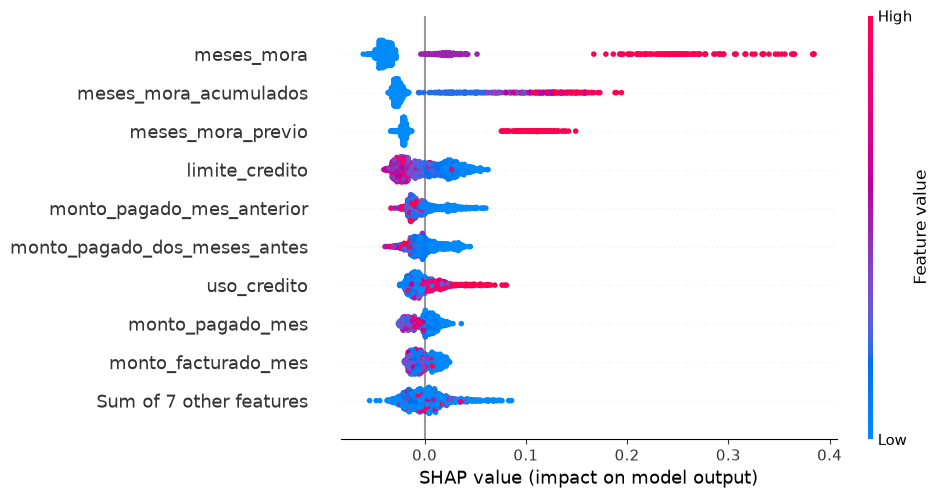

In [11]:
shap.plots.beeswarm(impago)

In [12]:
promedio = pd.Series(np.abs(impago.values).mean(axis=0), index=impago.feature_names)
promedio = promedio.sort_values(ascending=False)
display(Markdown(
    f'Las cuatro primeras: `{promedio.index[0]}`, `{promedio.index[1]}`, `{promedio.index[2]}` y '
    f'`{promedio.index[3]}`. La primera mueve, en promedio, **{num(100 * promedio.iloc[0], 1)} puntos** la '
    f'probabilidad de un cliente; la cuarta, {num(100 * promedio.iloc[3], 1)}. Las tres de mora '
    f'están correlacionadas y se reparten el crédito: se leen como un bloque de historial de pago.'
))

Las cuatro primeras: `meses_mora`, `meses_mora_acumulados`, `meses_mora_previo` y `limite_credito`. La primera mueve, en promedio, **5,8 puntos** la probabilidad de un cliente; la cuarta, 2,1. Las tres de mora están correlacionadas y se reparten el crédito: se leen como un bloque de historial de pago.

# Tiempo 2 · Lo hacemos juntos

## Explicación local: dos clientes contrastantes

El enjambre resume a todos. Cobranza pregunta por **uno**. Tomamos el cliente de prueba con la
probabilidad más alta y el de la más baja: `argmax` y `argmin` devuelven su **posición** en `X_test`.

<!-- contrato: accion=elegir-contrastes -->

In [13]:
alto = int(np.argmax(prob_test))   # posición del cliente con más riesgo
bajo = int(np.argmin(prob_test))   # posición del cliente con menos riesgo
id_alto = datos.loc[X_test.index[alto], 'id_cliente']
id_bajo = datos.loc[X_test.index[bajo], 'id_cliente']
display(Markdown(f'**{id_alto}**: {num(100 * prob_test[alto], 1)} % · **{id_bajo}**: '
                 f'{num(100 * prob_test[bajo], 1)} %.'))

**R-4696**: 84,7 % · **R-3751**: 0,5 %.

### Primero, la tabla de descomposición

Antes del gráfico, los números: el valor de cada variable del cliente de más riesgo y su aporte en
puntos, ordenados por tamaño sin importar el signo.

<!-- contrato: accion=tabla-descomposicion -->

In [14]:
descomposicion = pd.DataFrame({'valor': X_test_prep.iloc[alto],
                               'aporte (puntos)': 100 * impago.values[alto]})
descomposicion = descomposicion.sort_values('aporte (puntos)', key=abs, ascending=False)
descomposicion.head(6).round(1)

,valor,aporte (puntos)
meses_mora,2.0,26.6
meses_mora_acumulados,10.0,15.5
meses_mora_previo,2.0,10.4
uso_credito,0.6,2.9
limite_credito,50000.0,2.5
monto_pagado_mes,1900.0,1.2


In [15]:
moras = descomposicion.loc[['meses_mora', 'meses_mora_acumulados', 'meses_mora_previo'], 'aporte (puntos)']
display(Markdown(
    f'{id_alto} parte de la base, {num(100 * base, 1)} %, y sus aportes suman '
    f'**{pts(prob_test[alto] - base)} puntos**: llega a {num(100 * prob_test[alto], 1)} %. De esos puntos, '
    f'**{pts(moras.sum() / 100)}** vienen de las tres variables de mora.'
))

R-4696 parte de la base, 22,8 %, y sus aportes suman **+61,9 puntos**: llega a 84,7 %. De esos puntos, **+52,5** vienen de las tres variables de mora.

### La cascada: `shap.plots.waterfall`

`shap.plots.waterfall` dibuja esa misma tabla como una **cascada**: abajo, el valor base (`E[f(X)]`);
cada barra suma (rojo) o resta (azul) el aporte de una variable, y arriba queda la probabilidad del
cliente (`f(x)`). El gráfico escribe las cifras en **proporción, con punto decimal y dos decimales**:
`+0.27` son unos 27 puntos (26,6 en la tabla anterior). Las variables que pesan poco se agrupan en la
barra de más abajo, justo sobre el valor base.

<!-- contrato: accion=cascada-contraste -->

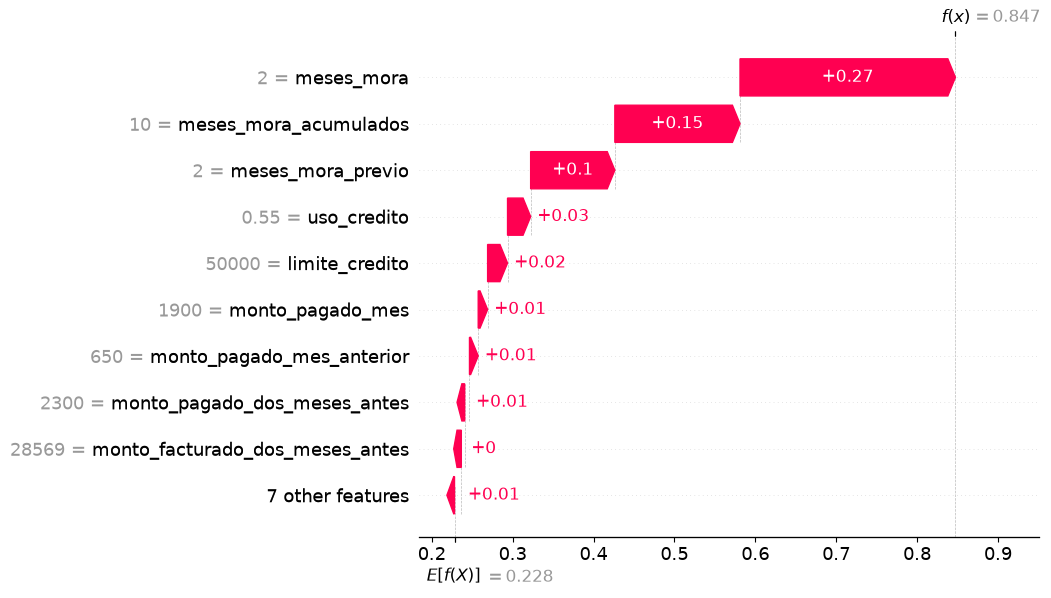

In [16]:
shap.plots.waterfall(impago[alto])

Ahora el cliente de menos riesgo. Antes de ejecutar: ¿qué variables esperan ver empujando hacia la
izquierda?

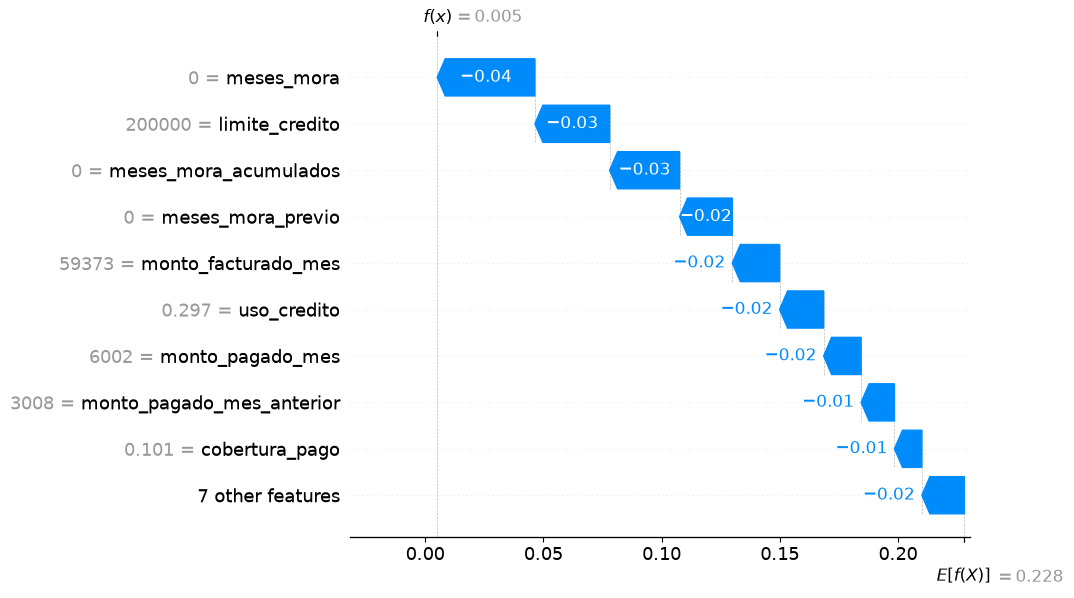

In [17]:
shap.plots.waterfall(impago[bajo])

In [18]:
display(Markdown(
    f'{id_bajo} parte de la misma base y sus aportes suman **{pts(prob_test[bajo] - base)} puntos**. Las '
    f'mismas variables, con otros valores, empujan hacia el otro lado: por eso la explicación global no '
    f'reemplaza a la local.'
))

R-3751 parte de la misma base y sus aportes suman **−22,3 puntos**. Las mismas variables, con otros valores, empujan hacia el otro lado: por eso la explicación global no reemplaza a la local.

## El gráfico de dependencia: `shap.plots.scatter`

`shap.plots.scatter` toma **una** variable y pone a cada cliente de prueba como un punto: en el eje
horizontal, su valor de `meses_mora`; en el vertical, el aporte que esa variable le dio. Con
`color=impago`, SHAP colorea los puntos con la **segunda variable** que más parece explicar la
dispersión vertical; su nombre aparece en la barra de color.

<!-- contrato: accion=dependencia -->

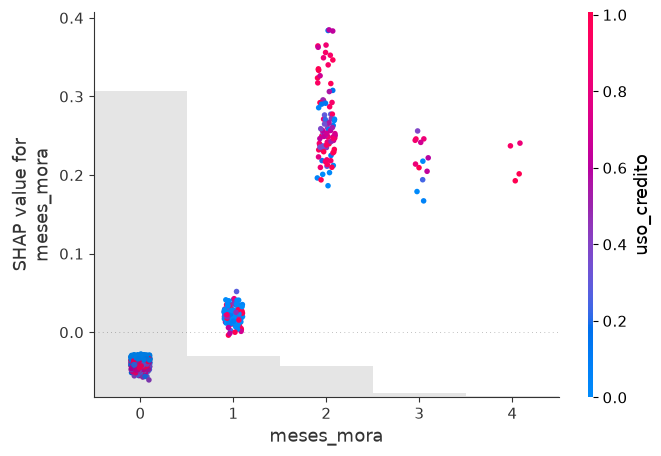

In [19]:
shap.plots.scatter(impago[:, 'meses_mora'], color=impago)

### El punto de quiebre, calculado

El aporte promedio de `meses_mora` en cada nivel, con cuántos clientes de prueba hay en cada uno.

<!-- contrato: accion=punto-quiebre -->

In [20]:
por_nivel = pd.DataFrame({'meses_mora': X_test_prep['meses_mora'],
                          'aporte (puntos)': 100 * impago[:, 'meses_mora'].values})
por_nivel = por_nivel.groupby('meses_mora')['aporte (puntos)'].agg(['mean', 'count'])
por_nivel.columns = ['aporte medio (puntos)', 'clientes']
por_nivel.round(1)

,aporte medio (puntos),clientes
meses_mora,,
0,-3.9,956
1,2.2,129
2,26.7,98
3,21.9,13
4,21.8,4


¿Entre qué niveles cambia más el aporte? `diff` resta cada fila de la anterior.

In [21]:
saltos = por_nivel['aporte medio (puntos)'].diff()   # cuánto cambia el aporte de un nivel al siguiente
mayor = saltos.idxmax()
pocos = por_nivel[por_nivel['clientes'] < 30].index
display(Markdown(
    f'El mayor salto ocurre al pasar a **{mayor} meses** de mora: **+{num(saltos.max(), 1)} puntos** de '
    f'aporte promedio. Los niveles con menos de 30 clientes ({", ".join(map(str, pocos))}) se leen con '
    f'cautela: su promedio descansa en pocos casos (es una heurística de tamaño, no un umbral exacto).'
))

El mayor salto ocurre al pasar a **2 meses** de mora: **+24,5 puntos** de aporte promedio. Los niveles con menos de 30 clientes (3, 4) se leen con cautela: su promedio descansa en pocos casos (es una heurística de tamaño, no un umbral exacto).

**Lo que este gráfico no dice.** Muestra cómo se asocian, en estos clientes, los meses de mora con lo
que el modelo predice. No dice qué pasaría si Cobranza **cambiara** la mora de un cliente: el modelo
aprendió que el atraso acompaña al impago, no qué ocurre si se elimina el atraso.

# Tiempo 3 · Lo hacen ustedes

## La actividad: auditar los peores errores

Los errores más informativos son los que el modelo cometió **con alta confianza**:

- **Falsas alarmas confiadas:** clientes que **pagaron** y a los que el modelo dio la probabilidad de
  impago más alta.
- **Incumplimientos no vistos:** clientes que **no pagaron** y a los que el modelo dio la probabilidad
  más baja.

1. **Ejecuten** la celda que aísla los 10 peores de cada tipo y lean las dos tablas.
2. **Miren la cascada** del peor caso de cada tipo y comparen qué variables lo empujaron.
3. **Completen la tabla diagnóstica** del final, con sus palabras.

**Criterio de éxito:** cada hipótesis nombra información que **el archivo no tiene** y que podría
explicar el error, y la última columna dice qué **no** se puede afirmar con estos datos.

**Evidencia observable:** las dos tablas, las dos cascadas y la tabla diagnóstica completa; el
**feedback formativo** llega en la puesta en común.

### Paso 1 · Los 10 peores de cada tipo

La tabla ya viene filtrada y ordenada: el trabajo es leerla, no construirla. La columna `posicion` es
el lugar del cliente en `X_test`, el que se usa para pedir su cascada.

<!-- contrato: accion=aislar-peores -->

In [22]:
MORAS = ['meses_mora', 'meses_mora_previo', 'meses_mora_acumulados']
resultado = datos.loc[X_test.index, ['id_cliente'] + MORAS + ['limite_credito', 'uso_credito']]
resultado['probabilidad'] = prob_test.round(3)
resultado['incumplio'] = y_test
resultado['posicion'] = np.arange(len(resultado))

In [23]:
pagaron = resultado[resultado['incumplio'] == 0]
falsas_alarmas = pagaron.sort_values('probabilidad', ascending=False).head(10)
falsas_alarmas

,id_cliente,meses_mora,meses_mora_previo,meses_mora_acumulados,limite_credito,uso_credito,probabilidad,incumplio,posicion
3259,R-3260,3,2,10,100000,0.3919,0.819,0,542
3367,R-3368,2,2,13,50000,0.7286,0.796,0,141
2154,R-2155,2,2,10,30000,0.7320,0.796,0,748
1719,R-1720,2,2,6,50000,0.4075,0.792,0,151
1693,R-1694,2,2,6,140000,0.2152,0.784,0,1007
1495,R-1496,2,2,6,80000,0.2583,0.782,0,1193
3932,R-3933,2,2,10,300000,0.4399,0.732,0,576
2694,R-2695,2,2,6,50000,0.9111,0.714,0,161
2680,R-2681,2,2,4,50000,0.3811,0.711,0,52
681,R-0682,2,2,10,60000,0.8928,0.709,0,805


Y los que **no pagaron**, ordenados de la probabilidad más baja a la más alta: arriba, los que el
modelo menos esperaba.

In [24]:
no_pagaron = resultado[resultado['incumplio'] == 1]
no_vistos = no_pagaron.sort_values('probabilidad').head(10)
no_vistos

,id_cliente,meses_mora,meses_mora_previo,meses_mora_acumulados,limite_credito,uso_credito,probabilidad,incumplio,posicion
3781,R-3782,0,0,0,390000,0.3308,0.014,1,794
3933,R-3934,0,0,0,140000,0.6949,0.014,1,648
2942,R-2943,0,0,0,320000,0.0933,0.018,1,751
2012,R-2013,0,0,0,150000,0.3779,0.035,1,636
3232,R-3233,0,0,0,360000,0.2629,0.044,1,199
3083,R-3084,0,0,0,260000,0.6549,0.047,1,634
4606,R-4607,0,0,0,120000,0.9844,0.048,1,417
813,R-0814,0,0,0,420000,0.0314,0.052,1,451
5333,R-5334,0,0,0,130000,0.9422,0.052,1,1090
2781,R-2782,0,0,0,320000,0.0582,0.055,1,924


**Preguntas guía:** ¿qué tienen en común las 10 falsas alarmas en las columnas de mora? ¿Y los 10
incumplimientos no vistos? ¿Qué le faltaría saber al modelo para no equivocarse con ellos?

### Paso 2 · La cascada del peor caso de cada tipo

`iloc[0]` toma la primera fila de cada tabla, la peor. Cambien el 0 por otro número para mirar otro caso.

<!-- contrato: accion=cascada-error -->

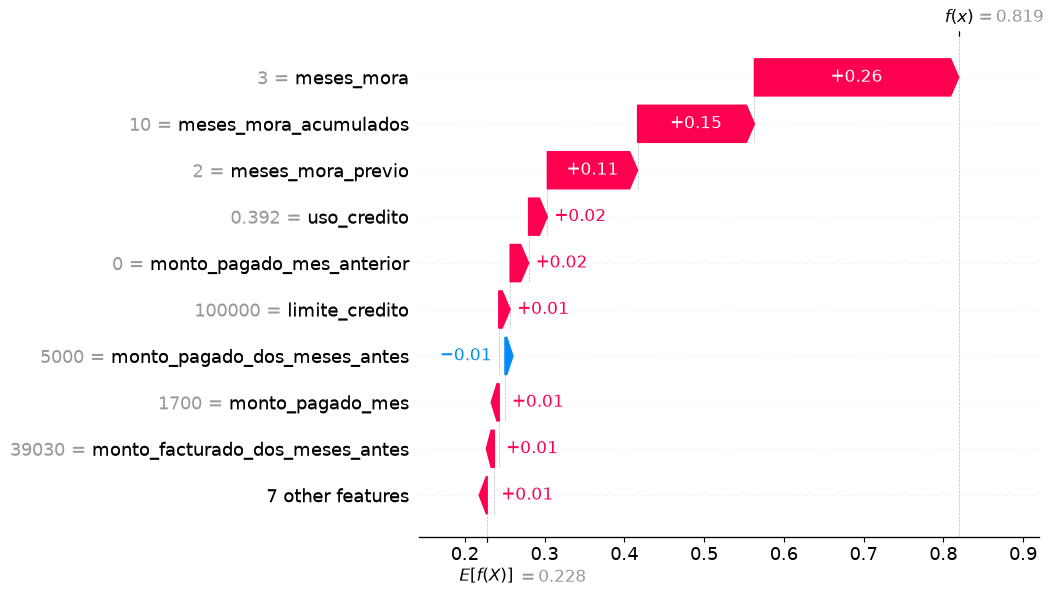

In [25]:
caso = falsas_alarmas['posicion'].iloc[0]   # la falsa alarma más confiada
shap.plots.waterfall(impago[caso])

El incumplimiento menos esperado. Comparen: ¿qué variables lo dejaron tan abajo de la base?

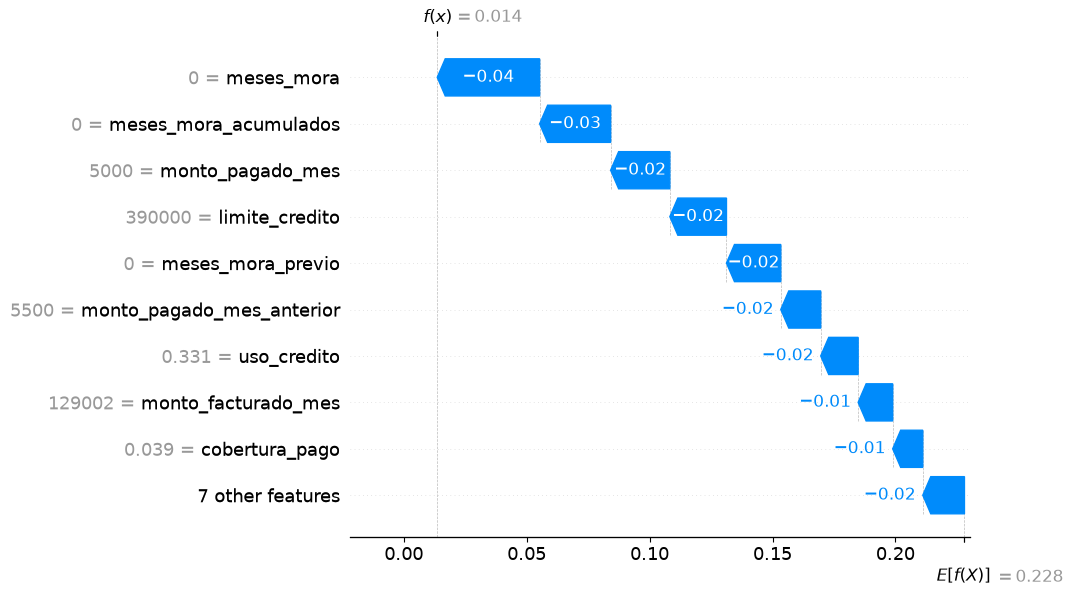

In [26]:
caso = no_vistos['posicion'].iloc[0]        # el incumplimiento menos esperado
shap.plots.waterfall(impago[caso])

### Paso 3 · La tabla diagnóstica

Hagan doble clic en esta celda para completarla. Una hipótesis es una **información ausente**, no una
causa demostrada.

| Tipo de error | Qué comparten (dato de las tablas) | Hipótesis: qué información falta en el archivo | Qué NO podemos afirmar |
|:--|:--|:--|:--|
| Falsas alarmas confiadas |  |  |  |
| Incumplimientos no vistos |  |  |  |

**Límite del modelo, en una frase:**

# Cierre

## Lo que le podemos responder a Cobranza, y lo que no

- **Sí:** descomponer con exactitud por qué el modelo marcó a un cliente, partiendo del valor base y
  sumando el aporte de cada variable, y usar esa probabilidad para **priorizar** a quién llamar primero.
- **No:** prometer que cambiar una variable —condonar la cuota atrasada, subir el límite— bajará el
  riesgo real. SHAP explica **al modelo**, no al mundo; saber qué pasa al intervenir exige un
  experimento.
- **Y sus errores marcan su frontera:** el modelo no puede anticipar lo que sus variables no registran.

## Atribución de datos

- **Creador:** Yeh, I. C., & Lien, C. H. (2009)
- **Fuente:** [UCI Machine Learning Repository — *Default of Credit Card Clients*, dataset 350](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients)
- **Licencia:** [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/)
- **Modificación:** obra derivada. Se tomaron 6.000 registros y 16 columnas del original de 30.000 ×
  25, con los nombres traducidos al español en `snake_case`, la escolaridad recodificada a etiquetas y
  dos razones derivadas nuevas. Los
  atributos sexo y estado civil se excluyeron deliberadamente.